# Stage 1: geometry-only baseline

Each face is classified independently using its UV-grid, a shared face CNN, and the classifier. This notebook builds the model and checks output shapes on a small training subset. Training is not run.

Sources: [UV-Net Sections 3.2 and 4.4](https://openaccess.thecvf.com/content/CVPR2021/papers/Jayaraman_UV-Net_Learning_From_Boundary_Representations_CVPR_2021_paper.pdf), [released surface encoder](https://github.com/AutodeskAILab/UV-Net/blob/main/uvnet/encoders.py). The explicit `nn.Module`, `forward`, and Linear/ReLU pattern follows the course's `06_Graph_Convnets/code02_dgl_solution.ipynb`.


VM version: use the gnn_project environment and install this package before opening the notebook.

Final prediction exports include ordered sample IDs, per-row sample indices and zero-based graph face indices. These are checked against annotation labels; STEP viewer face identity is a separate mapping.


In [ ]:
from pathlib import Path
import sys


import torch
from torch import nn

from uvnet_project.checkpointing import (
    seed_everything, save_training_checkpoint, load_training_checkpoint,
)
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.classifier import Classifier
from uvnet_project.load_mfcad import load_mfcad


## Reproducibility and epoch-boundary resume

Set `seed` and `resume_checkpoint` in the settings cell. Fresh runs seed Python, NumPy, Torch CPU/CUDA before initializing weights and again when starting a fresh training run. The training cell creates a fresh model when `resume_checkpoint=None`.

After **every completed epoch**, `epoch_NNN/model_weights.pt` contains model weights; `epoch_NNN/checkpoint.pt` contains weights, optimizer, AMP scaler where used, seed, Python/NumPy/Torch CPU/CUDA RNG states, histories and configuration. Checkpoints are written atomically. Laplacian checkpoints also include the frozen CNN state and baseline checkpoint hash; the feature cache must be retained to preserve eigenbases.

To resume: restart the kernel, set `resume_checkpoint` to the desired `checkpoint.pt`, run preparation cells, then the training cell. Set `num_epochs` to the **total target**, e.g. 20 to continue epoch 10 through epoch 20. Resume restores RNG states immediately before the epoch loop, rather than resetting the seed each epoch. Loss curves and step counts continue from the stored histories. A partial epoch is rerun from the most recent completed checkpoint. The same run folder is reused.

Use the same dataset order, cached features, software, GPU and training settings for reproducible replay. Deterministic settings disable cuDNN autotuning and TF32; restart the kernel before using them if CUDA was already initialized. Existing checkpoints created before this change lack RNG states: they can supply weights, but cannot provide exact trajectory resume. Training has not been started by these edits.


## Model settings

Segmentation uses 10 x 10 surface grids with seven channels: xyz, outward unit normals, and trimming mask. The paper uses 64-dimensional face embeddings. The classifier hidden dimension below is provisional, not specified by the paper.


In [ ]:
seed = 0
deterministic = True
# None starts a new seeded run. To resume, set the completed epoch checkpoint:
# resume_checkpoint = DATA_DIR.parent.parent / "results/baseline_run_01/epoch_010/checkpoint.pt"
resume_checkpoint = None
seed_everything(seed, deterministic=deterministic)

in_channels = 7
embedding_dim = 64
hidden_dim = 128
num_classes = 16

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## Face CNN and classifier

The encoder follows the paper and released code:

`Conv2d(7, 64, 3) -> Conv2d(64, 128, 3) -> Conv2d(128, 256, 3) -> AdaptiveAvgPool2d(1) -> Linear(256, 64)`

Each convolution and final linear projection has no bias, followed by batch normalization and LeakyReLU (negative slope 0.01). Padding of 1 preserves grid dimensions. Weights use the released encoder's Kaiming uniform initialization.

The existing classifier is `Linear(embedding_dim, hidden_dim) -> ReLU -> Linear(hidden_dim, 16)`. It follows the paper's two-layer description; the released head instead has three linear layers with batch normalization and dropout. This baseline uses no edge geometry, adjacency, or global shape embedding.


In [9]:
face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
classifier = Classifier(embedding_dim=embedding_dim, hidden_dim=hidden_dim,
                        num_classes=num_classes)
model = nn.Sequential(face_cnn, classifier).to(device)
print(model)
print("Number of parameters:", sum(p.numel() for p in model.parameters()))


Sequential(
  (0): FaceCNN(
    (conv1): Sequential(
      (0): Conv2d(7, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (pool): AdaptiveAvgPool2d(output_size=(1, 1))
    (fc): Sequential(
      (0): Linear(in_features=256, out_features=64, bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_ru

## Small input batch

Load two solids from the official training split. Stored grids have layout `(faces, U, V, channels)`; convolutions expect `(faces, channels, U, V)`. Labels follow the loader's aligned face annotations. Concatenation preserves solid and face order.

The trimming mask is passed as a channel, as in the released encoder. Coordinates are already normalized in the supplied dataset.


In [10]:
samples = load_mfcad("train", head=2)
face_grids = torch.cat([
    sample["graph"].ndata["x"] for sample in samples
]).permute(0, 3, 1, 2).contiguous().float()
labels = torch.tensor([
    face["segment"]["index"]
    for sample in samples
    for face in sample["faces"]
], dtype=torch.long)

print("Face grids:", tuple(face_grids.shape))
print("Labels:", tuple(labels.shape))
assert face_grids.shape[1:] == (in_channels, 10, 10)
assert len(face_grids) == len(labels)
assert labels.min() >= 0 and labels.max() < num_classes


Face grids: (36, 7, 10, 10)
Labels: (36,)


## Forward-pass check

Evaluation mode and disabled gradients ensure no changes to weights or batch-normalization statistics. These untrained outputs are used only to check shapes and finite values.


In [11]:
model.eval()
with torch.no_grad():
    embeddings = face_cnn(face_grids.to(device))
    logits = classifier(embeddings)
    probabilities = torch.softmax(logits, dim=1)

assert embeddings.shape == (len(labels), embedding_dim)
assert logits.shape == (len(labels), num_classes)
assert torch.isfinite(logits).all()
assert torch.allclose(probabilities.sum(dim=1), torch.ones(len(labels), device=device))
print("Face embeddings:", tuple(embeddings.shape))
print("Class logits:", tuple(logits.shape))
print("Forward-pass check passed.")


Face embeddings: (36, 64)
Class logits: (36, 16)
Forward-pass check passed.


## Training and checkpoint evaluation
20 epochs; 128 solids per batch. Cache train/validation tensors in RAM once. Use CUDA mixed precision, channels-last layout and deterministic cuDNN settings without changing the CNN architecture.

Training loss and accuracy accumulate during the training pass, weighted by face count; they are not fixed-checkpoint evaluation scores. Validation uses evaluation mode and mixed precision at each checkpoint. Save batch losses in `batch_loss.csv` and checkpoint metrics in `history.csv`. Final prediction files use the float32 evaluator and may differ slightly from mixed-precision metrics.

Final train/validation predictions are saved only once after training. Plot losses afterward. Matching output files are overwritten. With `resume_checkpoint=None`, the training cell reconstructs a fresh seeded model. Set an epoch checkpoint path to resume instead.


In [ ]:
import csv
from pathlib import Path

from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits
from uvnet_project.evaluation import evaluate

num_epochs = 20
learning_rate = 0.001
batch_size = 128  # solids; number of faces varies
run_dir = DATA_DIR.parent.parent / "results" / "baseline_run_01"
run_dir.mkdir(parents=True, exist_ok=True)

use_amp = device.type == "cuda"
if use_amp:
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

class FaceDataset(Dataset):
    def __init__(self, split):
        self.sample_ids = _load_splits()[split]
        self.samples = []
        # Load only once, rather than reading graphs/JSON every epoch.
        for sample_id in tqdm(self.sample_ids, desc=f"Cache {split}"):
            sample = _load_sample(sample_id)
            grids = sample["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float()
            labels = torch.tensor([face["segment"]["index"]
                                   for face in sample["faces"]], dtype=torch.long)
            self.samples.append((grids, labels))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]


def collate_faces(batch):
    grids, labels = zip(*batch)
    return torch.cat(grids), torch.cat(labels)


# Reuse the RAM cache when rerunning this cell in the same kernel.
if "train_dataset" not in globals() or not hasattr(train_dataset, "samples"):
    train_dataset = FaceDataset("train")
if "evaluation_dataset" not in globals() or not hasattr(evaluation_dataset, "samples"):
    evaluation_dataset = FaceDataset("validation")

loader_options = dict(batch_size=batch_size, collate_fn=collate_faces,
                      num_workers=0, pin_memory=use_amp)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
evaluation_loader = DataLoader(evaluation_dataset, shuffle=False, **loader_options)

seed_everything(seed, deterministic=deterministic)
if resume_checkpoint is None:
    face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
    classifier = Classifier(embedding_dim, hidden_dim, num_classes)
    model = nn.Sequential(face_cnn, classifier)
model = model.to(device)
if use_amp:
    model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()
history = []
batch_history = []
global_step = 0

run_config = dict(stage="baseline", seed=seed, deterministic=deterministic,
                  in_channels=in_channels, embedding_dim=embedding_dim,
                  hidden_dim=hidden_dim, num_classes=num_classes,
                  learning_rate=learning_rate, batch_size=batch_size,
                  mixed_precision=use_amp, train_sample_ids=train_dataset.sample_ids,
                  validation_sample_ids=evaluation_dataset.sample_ids)
start_epoch = 1
if resume_checkpoint is not None:
    restored = load_training_checkpoint(
        resume_checkpoint, model, optimizer, expected_config=run_config, scaler=scaler,
    )
    start_epoch = restored["epoch"] + 1
    history = restored["history"]
    batch_history = restored["batch_history"]
    global_step = batch_history[-1]["step"] if batch_history else 0
    if num_epochs < start_epoch:
        raise ValueError("Set num_epochs above the completed checkpoint epoch to continue training.")
    print(f"Resuming at epoch {start_epoch}; target is epoch {num_epochs}.")


def move_batch(grids, labels):
    grids = grids.to(device, non_blocking=True)
    if use_amp:
        grids = grids.contiguous(memory_format=torch.channels_last)
    return grids, labels.to(device, non_blocking=True)


@torch.no_grad()
def validation_metrics():
    model.eval()
    total_loss = torch.zeros((), device=device)
    total_correct = torch.zeros((), device=device, dtype=torch.long)
    total_faces = 0
    for grids, labels in tqdm(evaluation_loader, desc="Validation", leave=False):
        grids, labels = move_batch(grids, labels)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(grids)
            loss = loss_fn(logits, labels)
        total_loss += loss.detach() * labels.numel()
        total_correct += (logits.argmax(1) == labels).sum()
        total_faces += labels.numel()
    return total_loss.item() / total_faces, total_correct.item() / total_faces


for epoch in tqdm(range(start_epoch, num_epochs + 1), desc="Epochs"):
    model.train()
    epoch_losses, epoch_correct, epoch_sizes = [], [], []
    for grids, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
        grids, labels = move_batch(grids, labels)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(grids)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        # Keep small statistics on GPU; copy once per epoch, not every batch.
        epoch_losses.append(loss.detach())
        epoch_correct.append((logits.detach().argmax(1) == labels).sum())
        epoch_sizes.append(labels.numel())

    losses = torch.stack(epoch_losses).cpu().tolist()
    correct = torch.stack(epoch_correct).sum().item()
    faces = sum(epoch_sizes)
    for batch_index, (batch_loss, count) in enumerate(zip(losses, epoch_sizes), 1):
        global_step += 1
        batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                  loss=batch_loss, faces=count))
    train_loss = sum(loss * count for loss, count in zip(losses, epoch_sizes)) / faces
    train_accuracy = correct / faces

    validation_loss, validation_accuracy = validation_metrics()
    row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
               train_accuracy=train_accuracy, validation_loss=validation_loss,
               validation_accuracy=validation_accuracy)
    history.append(row)
    checkpoint_dir = run_dir / f"epoch_{epoch:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save_training_checkpoint(
        checkpoint_dir / "checkpoint.pt", model, optimizer, epoch=epoch, seed=seed,
        config={**run_config, "num_epochs": num_epochs, "checkpoint_every": 1},
        history=history, batch_history=batch_history, scaler=scaler,
        extra=dict(train_sample_ids=train_dataset.sample_ids, validation_sample_ids=evaluation_dataset.sample_ids),
    )
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
               f"accuracy {train_accuracy:.2%} | validation loss {validation_loss:.4f}, "
               f"accuracy {validation_accuracy:.2%}")
    with (run_dir / "batch_loss.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
        writer.writeheader()
        writer.writerows(batch_history)

# Full prediction collection happens only once, for the final model.
# Use the evaluator's float32 path for saved final results on both splits.
train_evaluation_loader = DataLoader(train_dataset, shuffle=False, **loader_options)
final_train_results = evaluate(model, train_evaluation_loader,
                               checkpoint_dir / "train_predictions.pt", device=device,
                               sample_ids=train_dataset.sample_ids, split="train")
final_validation_results = evaluate(model, evaluation_loader,
                                    checkpoint_dir / "validation_predictions.pt", device=device,
                                    sample_ids=evaluation_dataset.sample_ids, split="validation")
print(f"Finished. Final predictions and checkpoints: {run_dir}")


## Loss plot after training
Run after training finishes: training batch loss, its moving average, and validation loss at checkpoints.


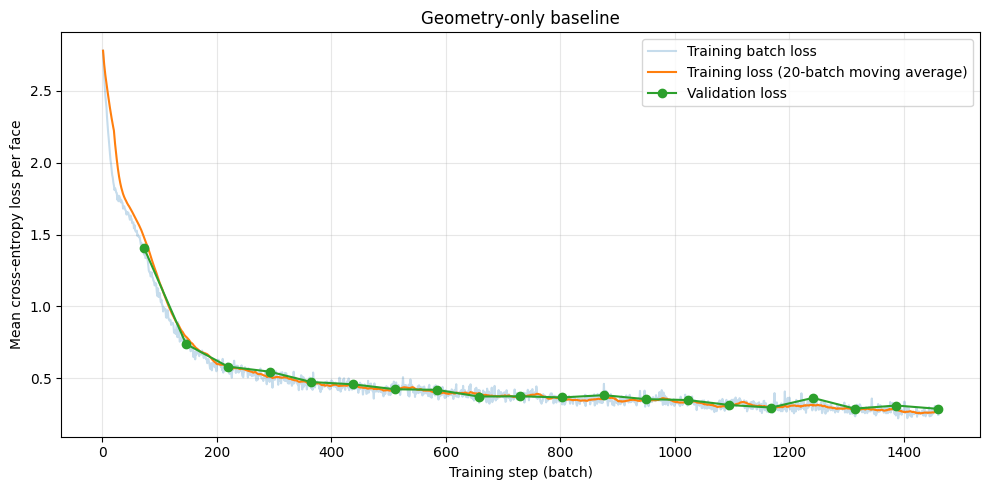

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

batch_log = pd.DataFrame(batch_history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(batch_log["step"], batch_log["loss"], alpha=0.25, label="Training batch loss")
ax.plot(batch_log["step"], batch_log["loss"].rolling(20, min_periods=1).mean(),
        label="Training loss (20-batch moving average)")
ax.plot([row["step"] for row in history],
        [row["validation_loss"] for row in history], marker="o", label="Validation loss")
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Mean cross-entropy loss per face")
ax.set_title("Geometry-only baseline")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "loss.png", dpi=150)
plt.show()


## IoU from final cached predictions
Run this cell after the final prediction files have been saved. It can also run independently after a kernel restart. Change `checkpoint_dir` to inspect another completed run. IoU = TP / (TP + FP + FN), aggregated over all faces in each split; mean IoU weights classes equally, includes stock, and excludes only classes with zero union. No model inference or training is run.


In [14]:
from pathlib import Path
import json
import pandas as pd
import torch
from IPython.display import display

from uvnet_project.load_mfcad import DATA_DIR

# Standalone: uses saved predictions, not the model or training variables.
checkpoint_dir = DATA_DIR.parent.parent / "results" / "baseline_run_01" / "epoch_020"

class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

class_rows = []
summary_rows = []
for split in ("train", "validation"):
    prediction_path = checkpoint_dir / f"{split}_predictions.pt"
    results = torch.load(prediction_path, map_location="cpu", weights_only=True)
    labels = results["labels"].long()
    predictions = results["predictions"].long()
    num_classes = results["probabilities"].shape[1]
    confusion = torch.bincount(
        labels * num_classes + predictions, minlength=num_classes**2
    ).reshape(num_classes, num_classes)
    intersection = confusion.diag()
    union = confusion.sum(1) + confusion.sum(0) - intersection
    # Undefined IoU (no true or predicted faces) is excluded from the mean.
    iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
    summary_rows.append({
        "split": split,
        "faces": labels.numel(),
        "accuracy": intersection.sum().item() / labels.numel(),
        "mean_iou": iou.nanmean().item(),
    })
    for index in range(num_classes):
        class_rows.append({
            "split": split, "class_index": index,
            "class_name": class_names.get(index, str(index)),
            "support": confusion[index].sum().item(),
            "intersection": intersection[index].item(),
            "union": union[index].item(), "iou": iou[index].item(),
        })

summary = pd.DataFrame(summary_rows).set_index("split")
per_class_iou = pd.DataFrame(class_rows)
display(summary.style.format({"accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
display(per_class_iou.pivot(index=["class_index", "class_name"],
                           columns="split", values="iou").style.format("{:.2%}"))
summary.to_csv(checkpoint_dir / "iou_summary.csv")
per_class_iou.to_csv(checkpoint_dir / "per_class_iou.csv", index=False)


/home/yongjun23/miniconda3/envs/gnn_project/lib/python3.11/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


,faces,accuracy,mean_iou
split,,,
train,209847,89.84%,80.17%
validation,70255,89.44%,79.42%


,split,train,validation
class_index,class_name,,
0,rectangular_through_slot,99.86%,99.46%
1,triangular_through_slot,50.15%,49.36%
2,rectangular_passage,72.42%,70.35%
3,triangular_passage,75.97%,76.05%
4,6sides_passage,99.81%,99.42%
5,rectangular_through_step,72.59%,71.27%
6,2sides_through_step,79.18%,78.56%
7,slanted_through_step,95.71%,95.55%
8,rectangular_blind_step,93.65%,93.88%
